# NATRE figure replication review

**Status: exact reproduction from the refreshed local archive has not yet been demonstrated.**

This notebook displays all ten figures saved in `plots_mixing_NATRE_gamman_analysis.ipynb` as **historical references**. They are the original saved PNGs, not new results from the local archive. Each has a separate location for a future Python-produced local result.

The November 9, 2026 local archive recovers the same 6,261 accepted physical profiles under the primary-sampling diagnostic. Small input-value and timestamp differences remain, and the production loader still needs its primary-sample correction. No scientific summary has been produced from that refreshed archive.

**Run All is read-only:** it reads existing reports and saved results, displays figures, and compares arrays if a candidate is explicitly supplied. It does not query servers, process Argo profiles, rerun bootstrap calculations, or start global processing. The old 4,980-profile local result is deliberately not selected as the refreshed result.

Use the **Argo_Feb_25** environment. The cells below use the existing `/swot` files and the adjacent `natre_figure_review.py` helper.


In [1]:
from pathlib import Path
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/argo-mixing-runtime/matplotlib")
os.environ.setdefault("NUMBA_CACHE_DIR", "/tmp/argo-mixing-runtime/numba")
os.environ.setdefault("XDG_CACHE_HOME", "/tmp/argo-mixing-runtime/cache")
os.environ.setdefault("PIP_CACHE_DIR", "/tmp/argo-mixing-runtime/pip")
import base64
import hashlib
import json
import sys
import warnings
warnings.filterwarnings("ignore", message="Engine 'erddapy' loading failed:.*")
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image, Code

candidates = [Path.cwd(), Path.cwd() / "notebooks/espe_code",
              Path("/home/amf2288/argo-intern/notebooks/espe_code")]
NOTEBOOK_DIR = next(p for p in candidates if (p / "natre_figure_review.py").is_file())
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))
from natre_figure_review import (compare_datasets, figure_requirements, render_summary_figure,
                                render_profile_figure)

SOURCE_NOTEBOOK = NOTEBOOK_DIR / "plots_mixing_NATRE_gamman_analysis.ipynb"
EXPECTED_SOURCE_SHA256 = "47b41ac83a360ba4a30b79acf5fcab9c725c5cccbdaad7f7bc9fabb46f7edfbb"
assert hashlib.sha256(SOURCE_NOTEBOOK.read_bytes()).hexdigest() == EXPECTED_SOURCE_SHA256, (
    "The original notebook has changed since this review was prepared. Review its changes "
    "before updating the recorded hash; saved images and current code may differ."
)
original_notebook = json.loads(SOURCE_NOTEBOOK.read_text())
DATA_ROOT = Path("/swot/SUM05/amf2288")
SNAPSHOT = DATA_ROOT / "argo_snapshots/gdac_20261109_138320"
REFRESH = DATA_ROOT / "argo_mixing/snapshot_refresh_20261111"
OLD_RUN = DATA_ROOT / "argo_mixing/natre_validation_20261110"
REFERENCE_SUMMARY = DATA_ROOT / "espe_code/NATRE_Argo_mixing_gamman.nc"

# Later: set this to the NEW completed run's local/ directory.
# None is intentional: the refreshed snapshot has no mixing summary yet.
LOCAL_STAGE = None
SHOW_PLOTTING_CODE = False
REDRAW_SAVED_REFERENCE_SUMMARIES = False
print("Read-only review. Refreshed local scientific result: not selected." if LOCAL_STAGE is None
      else f"Candidate stage: {LOCAL_STAGE}")


Read-only review. Refreshed local scientific result: not selected.


## Existing evidence

These are saved results from earlier work, not analyses launched by this notebook. Physical-profile agreement is distinct from exact input values, final scientific arrays, and rendered pixels.


In [2]:
snapshot_manifest = json.loads((SNAPSHOT / "snapshot_manifest.json").read_text())
input_audit = json.loads((REFRESH / "natre_refreshed_input_audit.json").read_text())
previous_validation = json.loads((OLD_RUN / "validation.json").read_text())
s = input_audit["summary"]
evidence = pd.DataFrame([
    ("Frozen global core snapshot", snapshot_manifest["status"],
     f'{snapshot_manifest["index_records"]:,} indexed profiles verified present'),
    ("Refreshed NATRE diagnostic population", "MATCH" if s["identity_population_matches"] else "MISMATCH",
     f'{s["primary_diagnostic_accepted_profiles"]:,} accepted identities; '
     f'{s["expected_profiles_missing_after_primary_diagnostic"]} missing; '
     f'{s["extra_profiles_after_primary_diagnostic"]} extra'),
    ("Refreshed exact numerical inputs", "MISMATCH", "Small P/T/S and timestamp differences remain"),
    ("Python replay on saved reference raw inputs", "PASSED previously", "34 profile variables across 6,261 profiles"),
    ("Old local scientific comparison", previous_validation["status"], "Old snapshot; 4,980 accepted profiles"),
    ("Refreshed local mixing figures", "NOT RUN" if LOCAL_STAGE is None else "CANDIDATE SELECTED",
     "No refreshed summary selected" if LOCAL_STAGE is None else "Provenance and equality checked below"),
    ("Global scientific processing", "NOT STARTED", "Await NATRE review and discussion"),
], columns=["Check", "Status", "Scope"])
display(evidence)


,Check,Status,Scope
0,Frozen global core snapshot,complete,"3,434,826 indexed profiles verified present"
1,Refreshed NATRE diagnostic population,MATCH,"6,261 accepted identities; 0 missing; 0 extra"
2,Refreshed exact numerical inputs,MISMATCH,Small P/T/S and timestamp differences remain
3,Python replay on saved reference raw inputs,PASSED previously,"34 profile variables across 6,261 profiles"
4,Old local scientific comparison,mismatch_global_blocked,"Old snapshot; 4,980 accepted profiles"
5,Refreshed local mixing figures,NOT RUN,No refreshed summary selected
6,Global scientific processing,NOT STARTED,Await NATRE review and discussion


## Candidate selection and strict array comparison

After a new NATRE run has been completed and discussed, set `LOCAL_STAGE` above to its `local/` directory. The checks below require the refreshed snapshot, the NATRE region/time range, and 6,261 profiles. They reject the old archive as a candidate.

The comparison checks dimensions, coordinates, missing variables, NaN masks, and values without tolerances or automatic coordinate alignment. Pipeline-only additional diagnostic variables are listed separately. Numerical equality does not establish identical PNG rendering or provenance by itself. The historical summary lacks some figure inputs, including the original pooled bootstrap draws, so agreement on its variables is not an all-figure proof.


In [3]:
with xr.open_dataset(REFERENCE_SUMMARY, engine="netcdf4") as opened:
    reference = opened.load()
candidate = None
comparison = None
candidate_manifest = None
if LOCAL_STAGE is None:
    display(Markdown("**PENDING:** no refreshed local summary has been selected. No equality claim is made."))
else:
    local_stage = Path(LOCAL_STAGE).expanduser().resolve()
    candidate_manifest = json.loads((local_stage / "manifest.json").read_text())
    cfg = candidate_manifest["config"]
    assert candidate_manifest["status"] == "complete", "Candidate profile stage is incomplete."
    assert cfg["source"] == "local", "Candidate must come from local GDAC inputs."
    assert Path(cfg["gdac"]).resolve() == SNAPSHOT.resolve(), "Candidate uses a different archive."
    assert cfg["bounds"] == [-38, -20, 19, 32], "Candidate region differs from NATRE."
    assert cfg["start"] == "2014-01-01" and cfg["end"] == "2024-01-01", "Candidate dates differ."
    assert candidate_manifest["accepted_profiles"] == 6261, "Candidate population count differs."
    with xr.open_dataset(local_stage / "summaries/region.nc", engine="netcdf4") as opened:
        candidate = opened.load()
    assert candidate.attrs.get("input_profile_count", candidate.attrs.get("input_profiles")) == 6261
    display(Markdown("**Candidate provenance:** " + str(local_stage)))
    display(pd.DataFrame([{"archive": cfg["gdac"], "profiles": candidate_manifest["accepted_profiles"],
                           "summary_seed": candidate.attrs.get("bootstrap_seed"),
                           "profile_code_sha256": cfg.get("code_sha256"),
                           "summary_code_sha256": candidate_manifest.get("summary_code_sha256")}]))
    comparison = compare_datasets(reference, candidate)
    display(comparison["summary"])
    display(pd.DataFrame(comparison["variables"]))


**PENDING:** no refreshed local summary has been selected. No equality claim is made.

## Figure-by-figure review

**Historical reference** always means the saved image embedded in the original notebook. These bytes are preserved exactly, but showing them is not independent reproduction. **Local candidate** always means saved output from the explicitly selected refreshed run.

The helper uses the original plotting code and the Python pipeline’s saved figure products. Cells 6, 10, and 23 substitute saved statistics for the original reductions; no bootstrap draws are generated. Cell 11 reads saved profile CT/SA arrays. Missing ingredients are reported explicitly. No reference values are substituted for missing local values. Optional reference-summary redraws are also labeled and are disabled by default.

The original notebook used an unsaved bootstrap random state. Its particular confidence bands cannot be independently regenerated bit-for-bit from raw data without those draws/state. Same-input, same-seed agreement is a separate validation target. Font and Matplotlib versions can also change pixels even when numerical plot inputs match.


In [4]:
FIGURES = [(6, 'Missing thermal dissipation by resolution bin'), (9, 'Dissipation and sampling-resolution sections'), (10, 'Mean stratification proxy and dissipation'), (11, 'Temperature–salinity and salinity–depth curves'), (17, 'Isopycnal slopes and geostrophic velocities'), (20, 'Regional mixing and hydrographic changes'), (21, 'Mean profiles and temporal percentile ranges'), (22, 'Mean profiles with standard-error bands'), (23, 'Mean profiles with pooled-bootstrap bands'), (24, 'Gradients and variance-production anomalies')]
SUMMARY_FIGURES = (6, 9, 10, 17, 20, 21, 22, 23, 24)
REFERENCE_REDRAW_CELLS = (20, 21, 22, 24)

def show_original_figure(cell_index):
    cell = original_notebook["cells"][cell_index]
    display(Markdown(f"**Historical reference — original cell index {cell_index}. Saved PNG; no recalculation.**"))
    images = [out["data"]["image/png"] for out in cell.get("outputs", [])
              if "image/png" in out.get("data", {})]
    if not images:
        raise ValueError(f"No saved image in original cell {cell_index}")
    for encoded in images:
        if isinstance(encoded, list):
            encoded = "".join(encoded)
        display(Image(data=base64.b64decode(encoded)))
    if SHOW_PLOTTING_CODE:
        display(Code("".join(cell["source"]), language="python"))

def show_local_figure(cell_index):
    if candidate is None:
        display(Markdown("**Local candidate: PENDING — refreshed scientific outputs have not been produced.**"))
        return
    if cell_index == 11:
        paths = candidate_manifest["regions"]["region"]
        # Same concatenation and time ordering used by the production summary.
        # Read saved CT/SA only; no processing of raw Argo profiles occurs.
        with xr.open_mfdataset(sorted(paths), combine="nested", concat_dim="time",
                               engine="netcdf4", data_vars="minimal", coords="minimal",
                               compat="override") as opened:
            profiles = opened[["CT", "SA"]].sortby("time")
            assert profiles.sizes["time"] == 6261
            display(Markdown("**Local candidate — saved profile CT/SA, original plotting code.**"))
            fig = render_profile_figure(profiles, source_notebook=SOURCE_NOTEBOOK)
            display(fig)
            plt.close(fig)
        return
    missing = figure_requirements(candidate, cell_index, source_notebook=SOURCE_NOTEBOOK)
    if missing:
        display(Markdown("**Local rendering unavailable; missing inputs:** `" + ", ".join(missing) + "`"))
        return
    display(Markdown("**Local candidate — saved Python-produced summary, original plotting code.**"))
    fig = render_summary_figure(candidate, cell_index, source_notebook=SOURCE_NOTEBOOK)
    display(fig)
    plt.close(fig)

def optionally_redraw_reference(cell_index):
    if REDRAW_SAVED_REFERENCE_SUMMARIES and cell_index in REFERENCE_REDRAW_CELLS:
        display(Markdown("**Optional redraw from saved historical summary — reference data, not local Argo reproduction.**"))
        fig = render_summary_figure(reference, cell_index, source_notebook=SOURCE_NOTEBOOK)
        display(fig)
        plt.close(fig)


### Missing thermal dissipation by resolution bin

Original notebook cell index `6` (zero-based).

**Historical reference — original cell index 6. Saved PNG; no recalculation.**

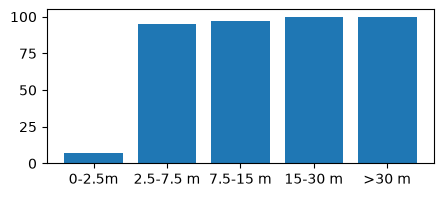

**Local candidate: PENDING — refreshed scientific outputs have not been produced.**

In [5]:
show_original_figure(6)
show_local_figure(6)
optionally_redraw_reference(6)


### Dissipation and sampling-resolution sections

Original notebook cell index `9` (zero-based).

**Historical reference — original cell index 9. Saved PNG; no recalculation.**

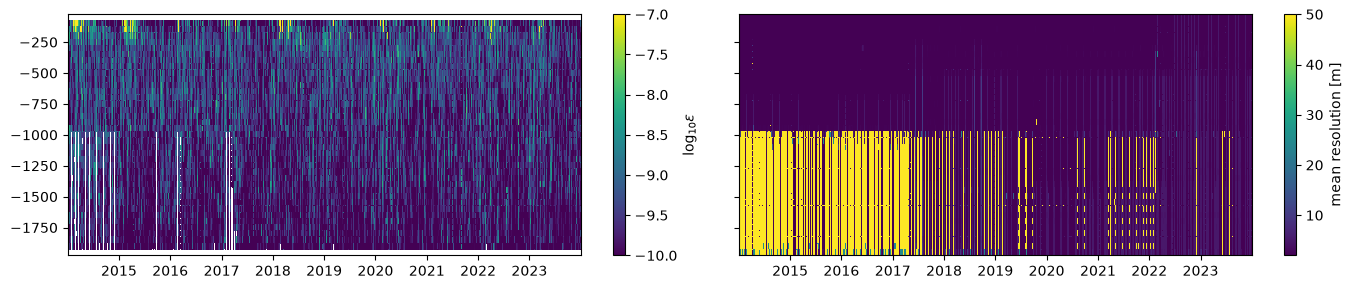

**Local candidate: PENDING — refreshed scientific outputs have not been produced.**

In [6]:
show_original_figure(9)
show_local_figure(9)
optionally_redraw_reference(9)


### Mean stratification proxy and dissipation

Original notebook cell index `10` (zero-based).

**Historical reference — original cell index 10. Saved PNG; no recalculation.**

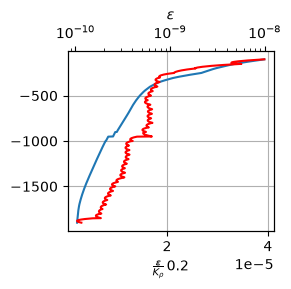

**Local candidate: PENDING — refreshed scientific outputs have not been produced.**

In [7]:
show_original_figure(10)
show_local_figure(10)
optionally_redraw_reference(10)


### Temperature–salinity and salinity–depth curves

Original notebook cell index `11` (zero-based).

**Historical reference — original cell index 11. Saved PNG; no recalculation.**

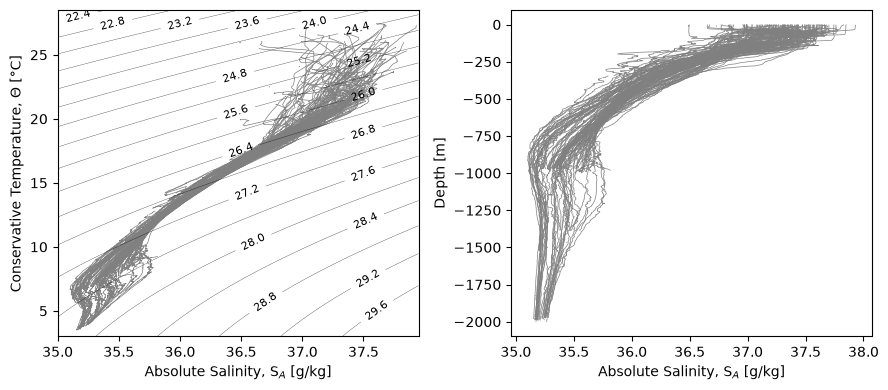

**Local candidate: PENDING — refreshed scientific outputs have not been produced.**

In [8]:
show_original_figure(11)
show_local_figure(11)
optionally_redraw_reference(11)


### Isopycnal slopes and geostrophic velocities

Original notebook cell index `17` (zero-based).

**Historical reference — original cell index 17. Saved PNG; no recalculation.**

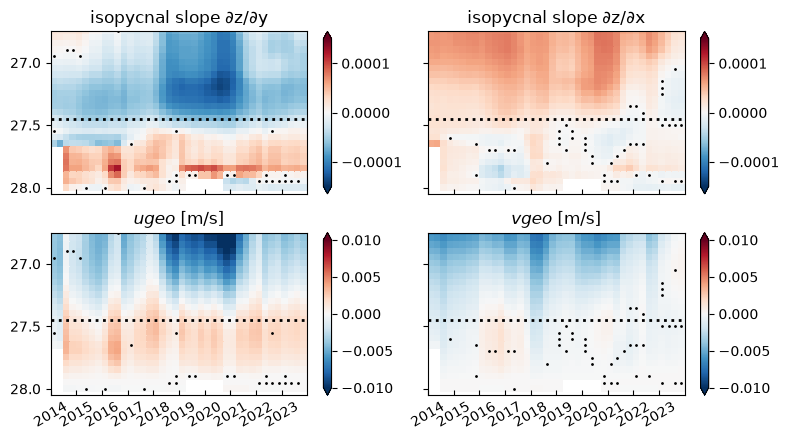

**Local candidate: PENDING — refreshed scientific outputs have not been produced.**

In [9]:
show_original_figure(17)
show_local_figure(17)
optionally_redraw_reference(17)


### Regional mixing and hydrographic changes

Original notebook cell index `20` (zero-based).

**Historical reference — original cell index 20. Saved PNG; no recalculation.**

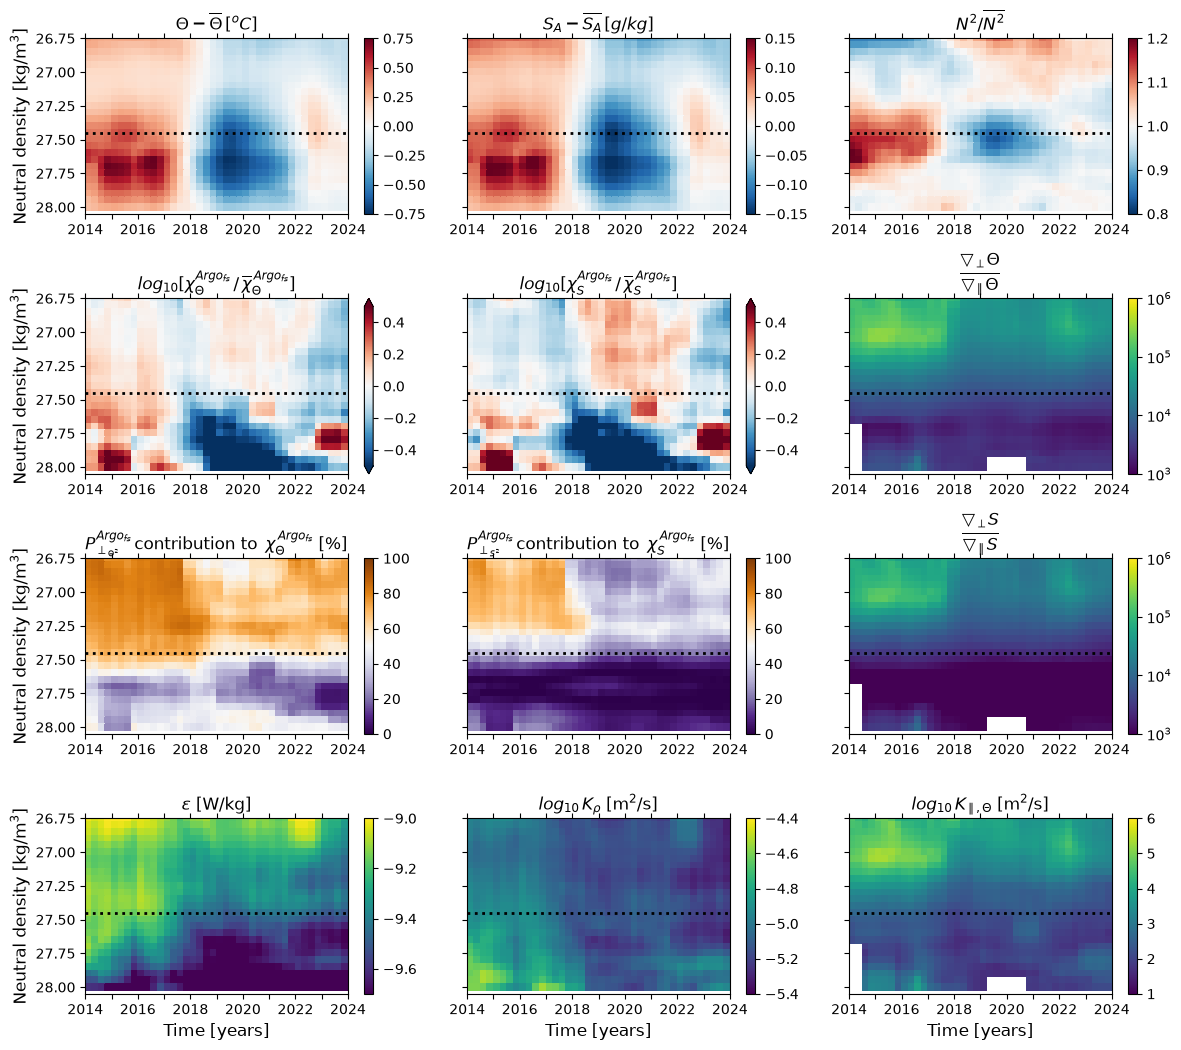

**Local candidate: PENDING — refreshed scientific outputs have not been produced.**

In [10]:
show_original_figure(20)
show_local_figure(20)
optionally_redraw_reference(20)


### Mean profiles and temporal percentile ranges

Original notebook cell index `21` (zero-based).

**Historical reference — original cell index 21. Saved PNG; no recalculation.**

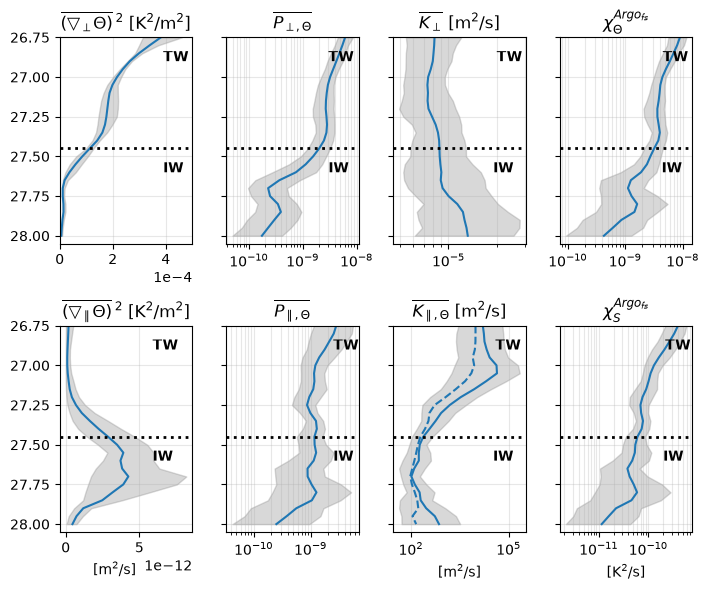

**Local candidate: PENDING — refreshed scientific outputs have not been produced.**

In [11]:
show_original_figure(21)
show_local_figure(21)
optionally_redraw_reference(21)


### Mean profiles with standard-error bands

Original notebook cell index `22` (zero-based).

**Historical reference — original cell index 22. Saved PNG; no recalculation.**

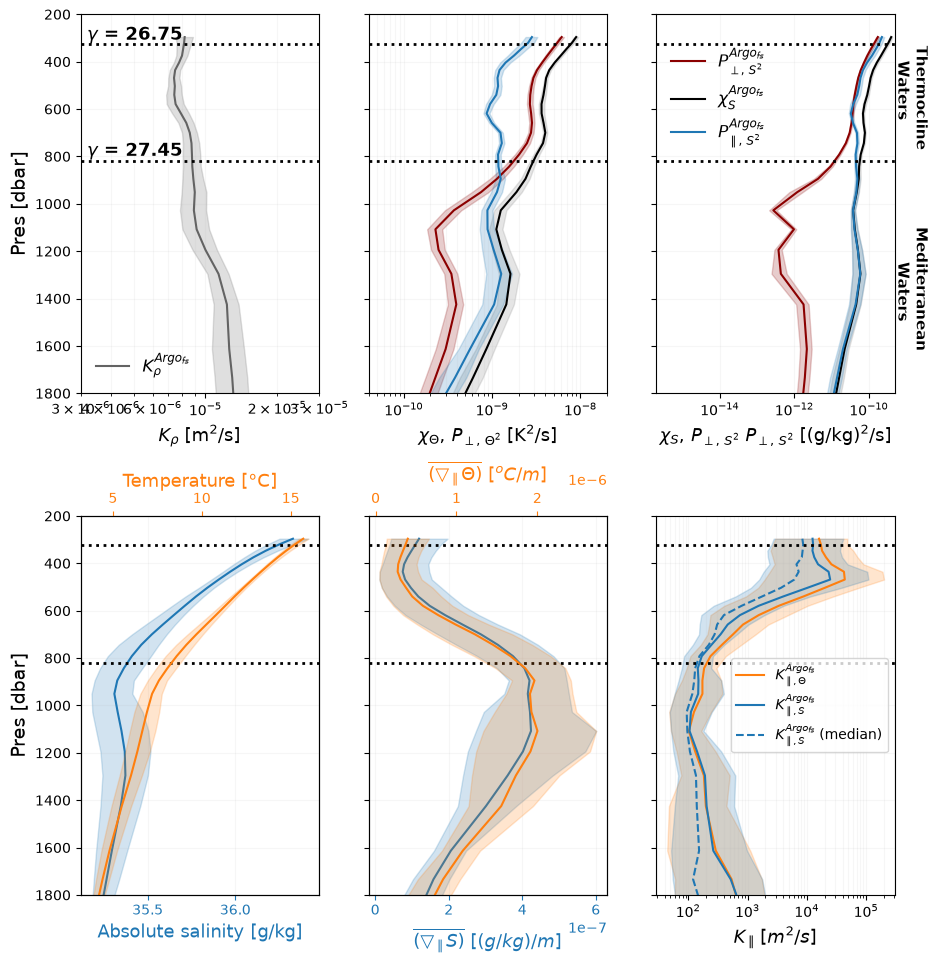

**Local candidate: PENDING — refreshed scientific outputs have not been produced.**

In [12]:
show_original_figure(22)
show_local_figure(22)
optionally_redraw_reference(22)


### Mean profiles with pooled-bootstrap bands

Original notebook cell index `23` (zero-based).

**Historical reference — original cell index 23. Saved PNG; no recalculation.**

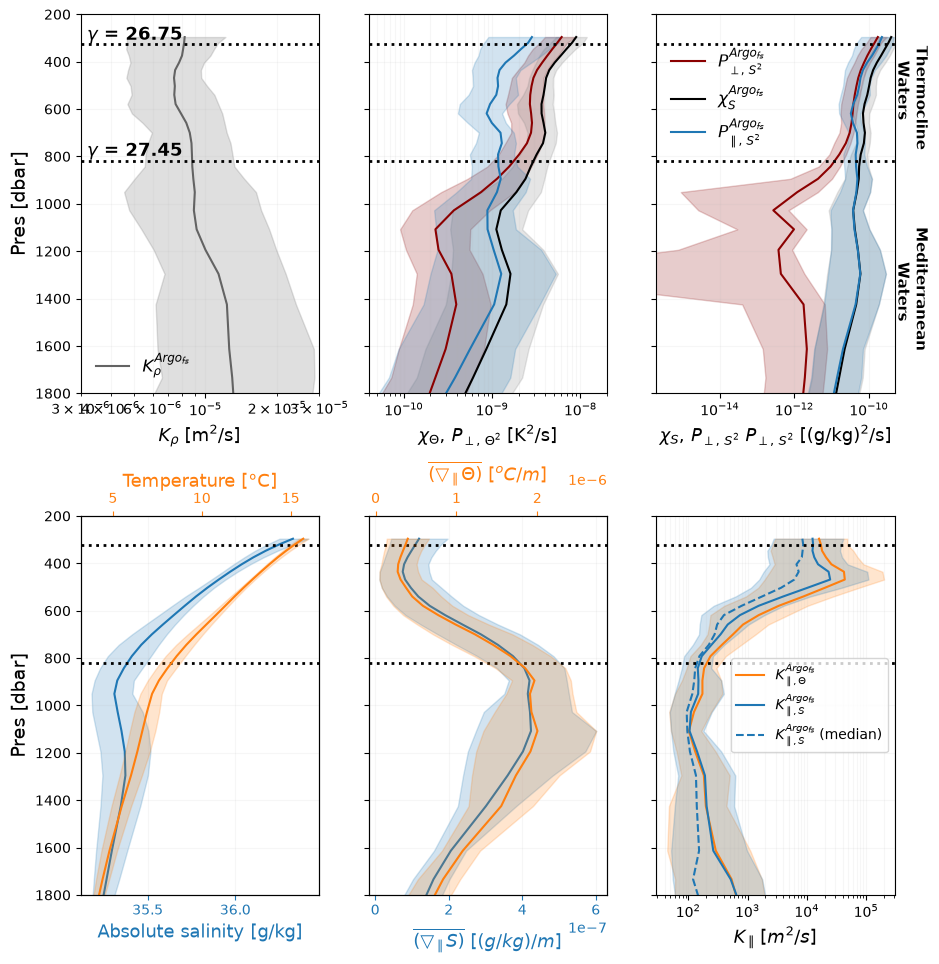

**Local candidate: PENDING — refreshed scientific outputs have not been produced.**

In [13]:
show_original_figure(23)
show_local_figure(23)
optionally_redraw_reference(23)


### Gradients and variance-production anomalies

Original notebook cell index `24` (zero-based).

**Historical reference — original cell index 24. Saved PNG; no recalculation.**

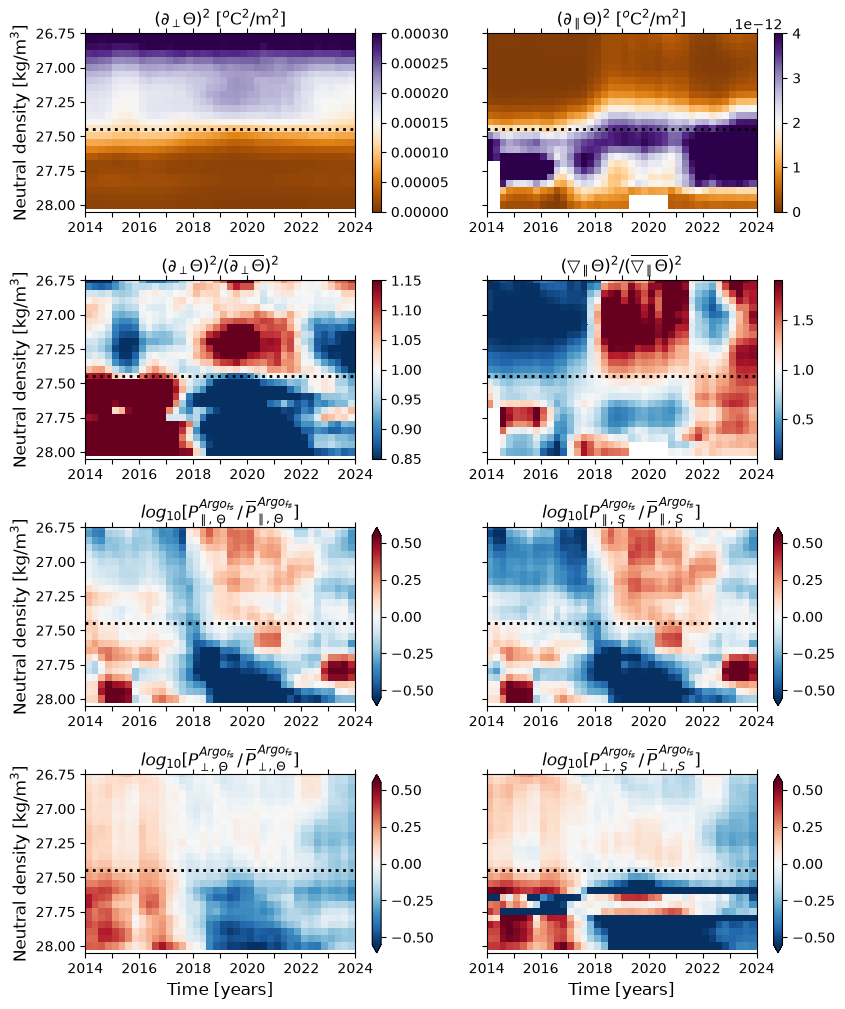

**Local candidate: PENDING — refreshed scientific outputs have not been produced.**

In [14]:
show_original_figure(24)
show_local_figure(24)
optionally_redraw_reference(24)


## Figure input inventory and next discussion

| Original cell indices | Required saved products | Current local redraw adapter |
| --- | --- | --- |
| 6 | Resolution-bin missing-χ percentages | Saved-statistic adapter |
| 9 | Cleaned ε section, mean resolution, profile times, Zfs | Implemented |
| 10 | Depth means of ε and ε/Kρ × 0.2 | Saved-statistic adapter |
| 11 | Full profile SA/CT/Z, every 50th profile; contour grid | Reads saved profile partitions; aggregated SA/CT cannot substitute |
| 17 | Slopes, velocities, and significance masks | Implemented |
| 20, 21, 22, 24 | Saved regional summary arrays | Implemented using original plotting cells |
| 23 | Saved pooled-bootstrap statistics, including distinct 0.5%/2.5% lower bounds | Saved-statistic adapter; historical summary lacks original draws |

Before claiming exact local reproduction, we still need to correct primary-sample loading, resolve the remaining input differences, run NATRE into a new output directory, review the figure adapters, and verify full-population scientific outputs with an agreed treatment of bootstrap randomness. The 100-profile seeded regression from earlier work is not a full-population replacement.

We will review NATRE together before considering global expansion. This notebook contains no global processing action.
